In [ ]:
######图2-1标准化时间戳
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# 加载合并后的数据集
print("正在加载数据...")
df = pd.read_csv("cleaned_sleep_data.csv")
# 显示原始时间戳的基本信息
print("\n原始时间戳统计信息:")
print(f"最小值: {df['time'].min()}")
print(f"最大值: {df['time'].max()}")
print(f"范围: {df['time'].max() - df['time'].min()}")
#  将所有时间戳转为正值
df['time_normalized'] = df['time'] - df['time'].min()
#  按照用户ID分组标准化时间戳
df['time_by_user'] = df.groupby('user_id')['time'].transform(
    lambda x: x - x.min()
)
# 检查标准化后的时间戳
print("\n标准化后时间戳统计信息:")
print(f"方案1 - 最小值: {df['time_normalized'].min()}")
print(f"方案1 - 最大值: {df['time_normalized'].max()}")
print(f"方案2 - 最小值: {df['time_by_user'].min()}")
print(f"方案2 - 最大值: {df['time_by_user'].max()}")
# 可视化时间戳分布
plt.figure(figsize=(12, 8))
plt.subplot(3, 1, 1)
plt.hist(df['time'], bins=50, alpha=0.7)
plt.title('原始时间戳分布')
plt.xlabel('时间戳')
plt.ylabel('频率')

plt.subplot(3, 1, 2)
plt.hist(df['time_normalized'], bins=50, alpha=0.7)
plt.title('全局标准化时间戳分布')
plt.xlabel('标准化时间戳')
plt.ylabel('频率')

plt.subplot(3, 1, 3)
plt.hist(df['time_by_user'], bins=50, alpha=0.7)
plt.title('按用户标准化时间戳分布')
plt.xlabel('标准化时间戳')
plt.ylabel('频率')

plt.tight_layout()
plt.savefig("时间戳标准化对比.png", dpi=300)
print("时间戳分布图已保存")
# 保存修正后的数据集
df_fixed = df.copy()
# 使用方案2的时间戳替换原始时间戳
df_fixed['time_original'] = df_fixed['time']  # 保留原始时间戳
df_fixed['time'] = df_fixed['time_by_user']   # 替换为按用户标准化的时间戳
df_fixed.drop(['time_normalized', 'time_by_user'], axis=1, inplace=True)
# 保存修正后的数据集
df_fixed.to_csv("cleaned_sleep_data_fixed_time.csv", index=False)
print("\n修正后的数据集已保存至: cleaned_sleep_data_fixed_time.csv")
# 转换时间戳为可读时间
def seconds_to_hms(seconds):
    """将秒数转换为时:分:秒格式"""
    hours = int(seconds // 3600)
    minutes = int((seconds % 3600) // 60)
    seconds = int(seconds % 60)
    return f"{hours:02d}:{minutes:02d}:{seconds:02d}"
# 添加可读时间列
df_fixed['readable_time'] = df_fixed['time'].apply(seconds_to_hms)
df_fixed[['time', 'readable_time']].head(10)
print("\n转换后的时间示例:")
print(df_fixed[['time', 'readable_time']].head(10))

正在加载数据...
计算睡眠质量指标...
分析各因素对睡眠质量的影响...


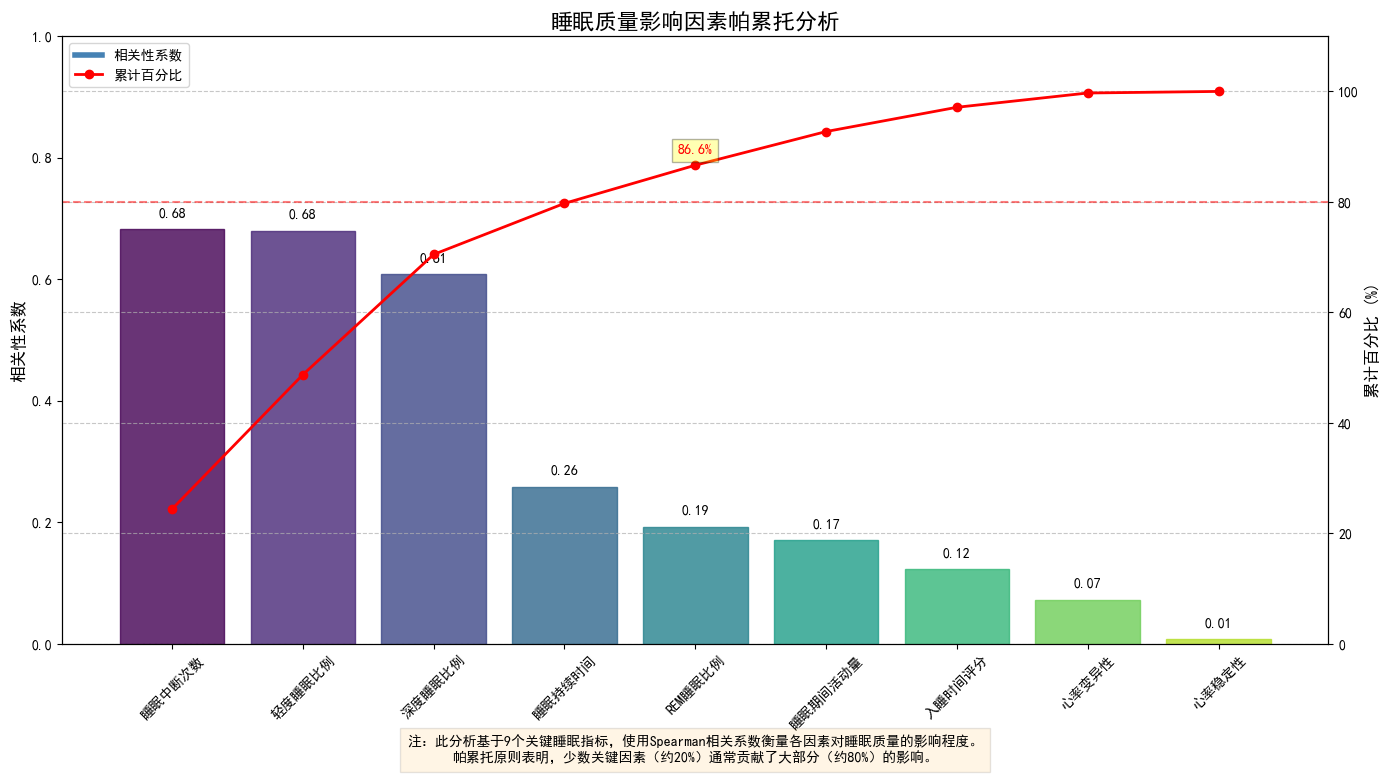


睡眠质量影响因素分析结果:
1. 睡眠中断次数: 相关性系数 0.682, 累计贡献率 24.4%
2. 轻度睡眠比例: 相关性系数 0.680, 累计贡献率 48.7%
3. 深度睡眠比例: 相关性系数 0.608, 累计贡献率 70.5%
4. 睡眠持续时间: 相关性系数 0.258, 累计贡献率 79.7%
5. REM睡眠比例: 相关性系数 0.193, 累计贡献率 86.6%
6. 睡眠期间活动量: 相关性系数 0.170, 累计贡献率 92.7%
7. 入睡时间评分: 相关性系数 0.123, 累计贡献率 97.1%
8. 心率变异性: 相关性系数 0.072, 累计贡献率 99.7%
9. 心率稳定性: 相关性系数 0.008, 累计贡献率 100.0%

根据帕累托原则(80/20法则)，影响睡眠质量的主要因素是: 睡眠中断次数, 轻度睡眠比例, 深度睡眠比例, 睡眠持续时间


In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号
# 加载标准化后的数据
print("正在加载数据...")
df = pd.read_csv("D:/2025-04/SleepDataSet/cleaned_sleep_data_fixed_time.csv")

# 确保时间列是正确的格式
df['time'] = pd.to_numeric(df['time'])
df['time_original'] = pd.to_numeric(df['time_original'])

# 定义更全面的睡眠质量评分函数
def calculate_sleep_quality_enhanced(df):
    """
    计算睡眠质量评分 - 增强版
    基于更多因素：
    1. 深度睡眠比例
    2. 轻度睡眠比例
    3. REM睡眠比例（如果有）
    4. 睡眠中断次数
    5. 心率稳定性
    6. 心率变异性
    7. 睡眠期间活动量
    8. 睡眠持续时间
    9. 睡眠规律性
    10. 入睡时间
    """
    # 按用户和日期分组
    # 使用数值时间创建日期标识符（不是真正的日期，只是为了分组）
    df['date_group'] = (df['time'] // 86400).astype(int)  # 假设每86400秒为一天
    sleep_quality = []
    
    for (user, date_group), group in df.groupby(['user_id', 'date_group']):
        # 计算各睡眠阶段比例
        sleep_states = group['sleep_state'].value_counts(normalize=True)
        deep_sleep_ratio = sleep_states.get(3, 0)  # 假设3代表深度睡眠
        light_sleep_ratio = sleep_states.get(2, 0)  # 假设2代表轻度睡眠
        rem_sleep_ratio = sleep_states.get(4, 0)  # 假设4代表REM睡眠（如果有）
        
        # 计算睡眠中断次数 (从深度/轻度睡眠到清醒的转换)
        sleep_transitions = group['sleep_state'].diff()
        interruptions = ((sleep_transitions == -2) | (sleep_transitions == -1)).sum()
        
        # 心率相关指标
        hr_stability = 1 / (group['heart_rate'].std() + 1)  # 心率稳定性
        hr_variability = group['heart_rate'].diff().abs().mean()  # 心率变异性
        
        # 睡眠期间活动量 (基于加速度和步数)
        movement = group[['x', 'y', 'z']].abs().mean().mean() + group['steps'].mean()
        
        # 睡眠持续时间 (小时)
        # 直接使用数值时间差计算小时
        sleep_duration = (group['time'].max() - group['time'].min()) / 3600
        
        # 睡眠规律性 (基于每天入睡时间的一致性)
        # 这里简单用当天最早记录的时间作为入睡时间
        # 将时间转换为一天中的小时 (0-24)
        sleep_start_hour = (group['time'].min() % 86400) / 3600  # 取模获取一天内的秒数，再转为小时
        
        # 入睡时间评分 (22-23点入睡为最佳，越偏离越低)
        ideal_sleep_time = 22.5  # 理想入睡时间：晚上10:30
        sleep_time_score = 1 - min(abs(sleep_start_hour - ideal_sleep_time), 12) / 12
        
        # 综合评分 (加权)
        quality_score = (
            0.25 * deep_sleep_ratio + 
            0.10 * light_sleep_ratio +
            0.10 * rem_sleep_ratio +
            0.15 * (1 / (interruptions + 1)) +  # 中断越少越好
            0.10 * hr_stability + 
            0.05 * (1 / (hr_variability + 1)) +  # 变异性越小越好
            0.10 * (1 / (movement + 1)) +  # 活动越少越好
            0.10 * min(sleep_duration / 8, 1) +  # 8小时为理想睡眠时长
            0.05 * sleep_time_score  # 入睡时间评分
        )
        
        sleep_quality.append({
            'user_id': user,
            'date_group': date_group,
            'deep_sleep_ratio': deep_sleep_ratio,
            'light_sleep_ratio': light_sleep_ratio,
            'rem_sleep_ratio': rem_sleep_ratio,
            'interruptions': interruptions,
            'hr_stability': hr_stability,
            'hr_variability': hr_variability,
            'movement': movement,
            'sleep_duration': sleep_duration,
            'sleep_time_score': sleep_time_score,
            'quality_score': quality_score
        })
    
    return pd.DataFrame(sleep_quality)

# 计算增强版睡眠质量
print("计算睡眠质量指标...")
sleep_quality_enhanced_df = calculate_sleep_quality_enhanced(df)

# 分析各因素对睡眠质量的影响
print("分析各因素对睡眠质量的影响...")

# 计算各因素与睡眠质量的相关性
factors = [
    'deep_sleep_ratio', 
    'light_sleep_ratio', 
    'rem_sleep_ratio',
    'interruptions', 
    'hr_stability', 
    'hr_variability',
    'movement', 
    'sleep_duration',
    'sleep_time_score'
]

correlations = {}

for factor in factors:
    # 使用Spearman相关系数，对非线性关系更稳健
    if factor in ['interruptions', 'movement', 'hr_variability']:
        # 这些因素是负向影响，所以取负值使相关性为正
        corr = -stats.spearmanr(sleep_quality_enhanced_df[factor], sleep_quality_enhanced_df['quality_score'])[0]
    else:
        corr = stats.spearmanr(sleep_quality_enhanced_df[factor], sleep_quality_enhanced_df['quality_score'])[0]
    
    correlations[factor] = abs(corr)  # 取绝对值，我们关注影响程度

# 创建增强版帕累托图
plt.figure(figsize=(14, 8))

# 按相关性排序
sorted_correlations = dict(sorted(correlations.items(), key=lambda x: x[1], reverse=True))

# 计算累计百分比
total = sum(sorted_correlations.values())
cumulative_percentage = np.cumsum([val/total*100 for val in sorted_correlations.values()])

# 设置x轴标签
factor_names = {
    'deep_sleep_ratio': '深度睡眠比例',
    'light_sleep_ratio': '轻度睡眠比例',
    'rem_sleep_ratio': 'REM睡眠比例',
    'interruptions': '睡眠中断次数',
    'hr_stability': '心率稳定性',
    'hr_variability': '心率变异性',
    'movement': '睡眠期间活动量',
    'sleep_duration': '睡眠持续时间',
    'sleep_time_score': '入睡时间评分'
}
plt.xticks(range(len(sorted_correlations)), [factor_names[factor] for factor in sorted_correlations.keys()], rotation=45)

# 设置双y轴
ax1 = plt.gca()
ax2 = ax1.twinx()
ax1.set_ylabel('相关性系数', fontsize=12)
ax2.set_ylabel('累计百分比 (%)', fontsize=12)
ax1.set_ylim(0, 1)  # 设置左侧Y轴范围为0到1
ax1.set_yticks(np.arange(0, 1.1, 0.2))  # 以0.2为步长设置刻度
ax2.set_ylim(0, 110)

# 绘制条形图（使用ax1）
bars = ax1.bar(range(len(sorted_correlations)), sorted_correlations.values(), color='steelblue', alpha=0.8)

# 为条形图添加渐变色
for i, bar in enumerate(bars):
    bar.set_color(plt.cm.viridis(i/len(sorted_correlations)))

# 绘制累计百分比线（使用ax2）
line = ax2.plot(range(len(sorted_correlations)), cumulative_percentage, 'ro-', linewidth=2)

# 添加80%参考线（使用ax2）
ax2.axhline(y=80, color='r', linestyle='--', alpha=0.5)

# 添加条形图数据标签（使用ax1）
for i, (factor, value) in enumerate(sorted_correlations.items()):
    ax1.text(i, value + 0.02, f'{value:.2f}', ha='center')

# 只在折线图上特殊标注第一个大于85%的点（使用ax2）
first_high_point_found = False
for i, (factor, value) in enumerate(sorted_correlations.items()):
    if cumulative_percentage[i] > 85 and not first_high_point_found:
        ax2.text(i, cumulative_percentage[i] + 2, f'{cumulative_percentage[i]:.1f}%', ha='center', 
                 fontweight='bold', color='red', bbox=dict(facecolor='yellow', alpha=0.3))
        first_high_point_found = True
        break

# 设置标题和网格
plt.title('睡眠质量影响因素帕累托分析', fontsize=16, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 添加图例
from matplotlib.lines import Line2D
custom_lines = [Line2D([0], [0], color='steelblue', lw=4),
                Line2D([0], [0], color='r', marker='o', lw=2)]
plt.legend(custom_lines, ['相关性系数', '累计百分比'], loc='upper left')

# 添加注释说明
plt.figtext(0.5, 0.01, 
           "注：此分析基于9个关键睡眠指标，使用Spearman相关系数衡量各因素对睡眠质量的影响程度。\n"
           "帕累托原则表明，少数关键因素（约20%）通常贡献了大部分（约80%）的影响。", 
           ha="center", fontsize=10, bbox={"facecolor":"orange", "alpha":0.1, "pad":5})

plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.savefig('睡眠质量多因素帕累托分析.png', dpi=300)
plt.show()

# 输出结果分析
print("\n睡眠质量影响因素分析结果:")
for i, (factor, value) in enumerate(sorted_correlations.items()):
    print(f"{i+1}. {factor_names[factor]}: 相关性系数 {value:.3f}, 累计贡献率 {cumulative_percentage[i]:.1f}%")

# 识别关键因素（80%原则）
key_factors = []
for i, (factor, value) in enumerate(sorted_correlations.items()):
    if cumulative_percentage[i] <= 80:
        key_factors.append(factor_names[factor])
    else:
        break

print(f"\n根据帕累托原则(80/20法则)，影响睡眠质量的主要因素是: {', '.join(key_factors)}")

